# **캐글 필사**
# Spaceship Titanic| EDA + Model - 100%

https://www.kaggle.com/code/lightonkalumba/spaceship-titanic-eda-model-100 

1. Import Basic Libraries
2. Load Data
3. Basic Data Exploration

In [2]:
#Import basic Libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import SimpleImputer

In [3]:
test=pd.read_csv("C:/Users/user/ESAA_YB/data/spaceship_titanic/test.csv")
train=pd.read_csv("C:/Users/user/ESAA_YB/data/spaceship_titanic/train.csv")

In [4]:
test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [5]:
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB


### 1. 식별자 및 개인 정보

- PassengerId: 각 승객의 고유 ID
- Name: 승객이름


### 2. 승객 특성 및 상태 변수

- HomePlanet: 승객이 원래 살던 출발지 
- CryoSleep: 승객이 항해 동안 냉동 수면(Cryogenic sleep) 상태(True/False)
- Cabin: 승객이 머문 객실 번호
- Destination: 우주선이 도착할 목적지 
- Age: 승객의 만 나이
- VIP: VIP 서비스 신청 여부(True/False)


### 3. 우주선 내부 부대시설 이용 금액 변수

- RoomService: 룸서비스 이용 요금
- FoodCourt: 푸드코트 지출 요금
- ShoppingMall: 쇼핑몰 지출 요금
- Spa: 스파 이용 요금
- VRDeck: 가상현실(VR) 데크 이용 요금


### 4. 예측 대상 (Target Variable)

- Transported: 무사히 수송(전송)되었는지 여부(True/False)


In [7]:
#Percentage of missing values in the dataset
missing_percentage = (train.isnull().sum() / len(train)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.312205
CryoSleep       2.496261
Cabin           2.289198
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Name            2.300702
Transported     0.000000
dtype: float64


In [8]:
#Percentage of missing values in the dataset
missing_percentage = (test.isnull().sum() / len(test)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.034136
CryoSleep       2.174421
Cabin           2.338087
Destination     2.151040
Age             2.127660
VIP             2.174421
RoomService     1.917232
FoodCourt       2.478373
ShoppingMall    2.291326
Spa             2.361468
VRDeck          1.870470
Name            2.197802
dtype: float64


결측치 비율 확인하기
-is.null을 이용해서 결측치 비율 확인하기 대략 1-2%정도

4. Exploratory Data Analysis

- 승객 수송 여부의 비율을 계산하는 파이 차트 시각화 : 클래스 불균형 문제를 확인하기 위함
- 승객 나이 분포에 대한 히스토그램 시각화
- vip 고객 비율 시각화
- 스캐터플롯 : LabelEncoder로 문자형->숫자형으로 변환, 푸드코트 지출 비용과 출발지(고향행성)의 관계를 산점도로 확인 

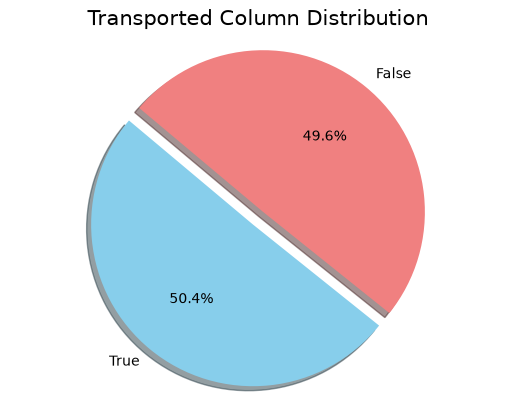

In [4]:
true_count = train['Transported'].sum()
false_count = len(train) - true_count

# Data for the pie chart
labels = ['True', 'False']
sizes = [true_count, false_count]
colors = ['skyblue', 'lightcoral']
explode = (0.1, 0)  

# Create the pie chart
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
autopct='%1.1f%%', shadow=True, startangle=140)

plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title("Transported Column Distribution", size = 15)
plt.show()

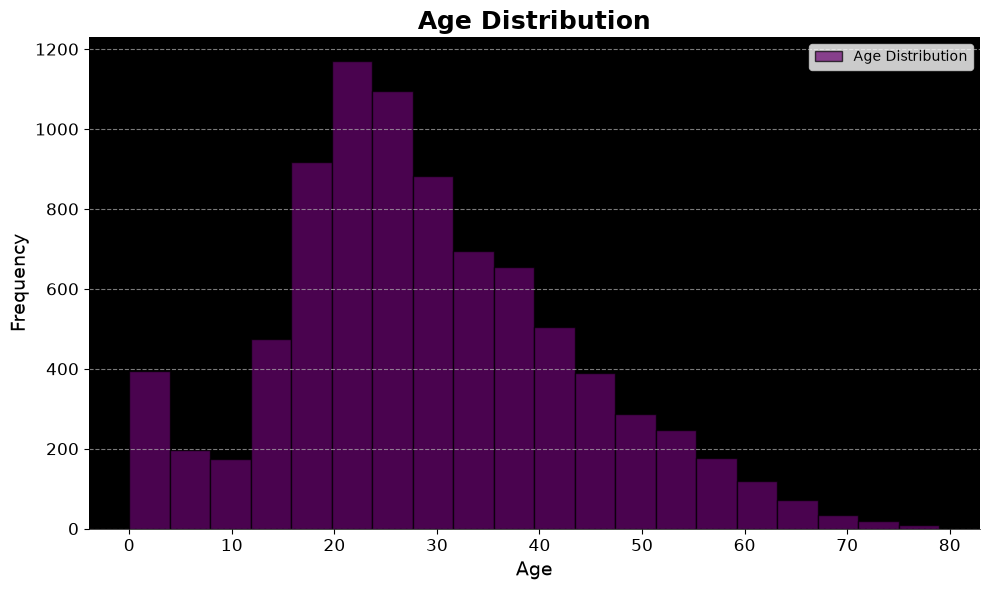

In [10]:
age_data = train['Age']

plt.figure(figsize=(10, 6))
plt.hist(age_data, bins=20, edgecolor='black', color='#6A0572', alpha=0.7, label='Age Distribution')

plt.title('Age Distribution', fontsize=18, fontweight='bold', color='black')
plt.xlabel('Age', fontsize=14, color='black')
plt.ylabel('Frequency', fontsize=14, color='black')

plt.xticks(fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.gca().set_facecolor('black')

# Remove unnecessary spines and set the layout
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(0.5)
plt.gca().spines['bottom'].set_linewidth(0.5)

# Add legend
plt.legend()

plt.tight_layout()

plt.show()

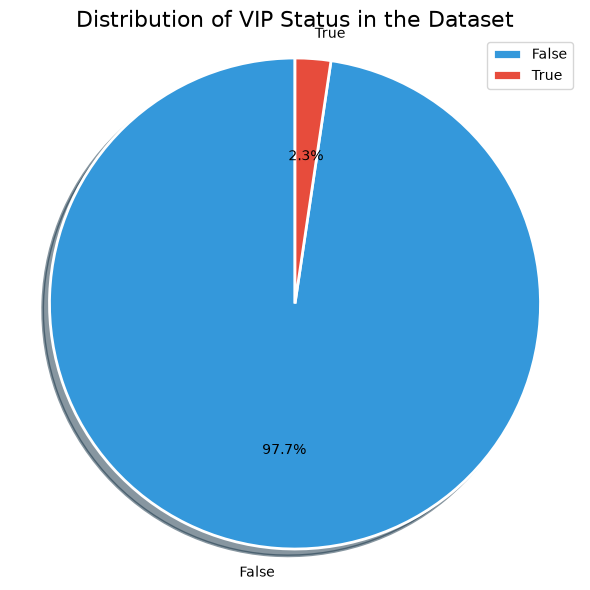

In [11]:
sex_counts = train['VIP'].value_counts()
colors = ['#3498db', '#e74c3c']

# Create the pie chart
plt.figure(figsize=(6, 6))
plt.pie(sex_counts, labels=sex_counts.index, colors=colors, autopct='%1.1f%%', startangle=90, shadow=True, wedgeprops={'linewidth': 2, 'edgecolor': 'white'})

# Add a title and legend
plt.title("Distribution of VIP Status in the Dataset", fontsize=16)
plt.legend(labels=sex_counts.index, loc='upper right')

# Equal aspect ratio ensures that pie is drawn as a circle.
plt.axis('equal')

# Show the pie chart
plt.tight_layout()
plt.show()

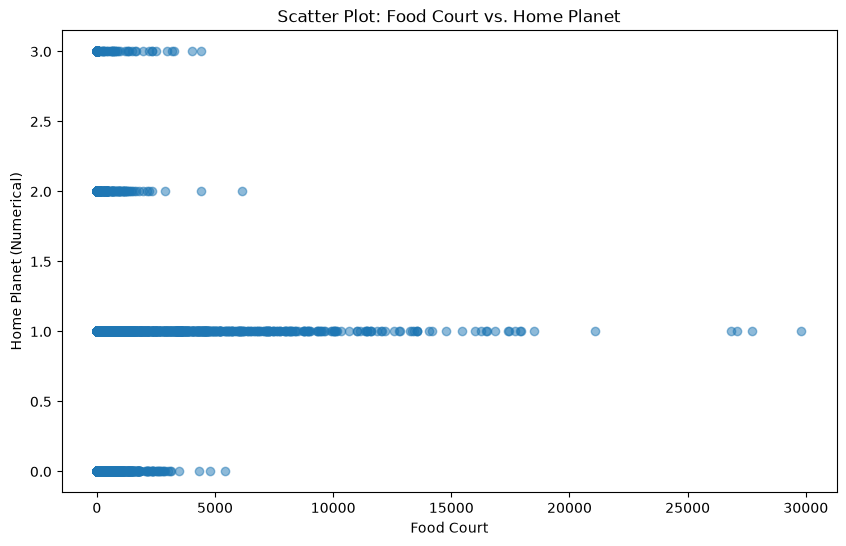

In [12]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

food_court = train['FoodCourt']
home_planet = train['HomePlanet']


label_encoder = LabelEncoder()
home_planet_numerical = label_encoder.fit_transform(home_planet)

# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(food_court, home_planet_numerical, alpha=0.5)

plt.xlabel('Food Court')
plt.ylabel('Home Planet (Numerical)')
plt.title('Scatter Plot: Food Court vs. Home Planet')

# Show the plot
plt.show()

5. Data Preprocessing

- 범주형 변수 수치화하기 : LabelEncoder 이용
- 독립변수와 타겟변수 분리하기 : pd.concat 이용하여 수치형 컬럼 합쳐서 독립변수 구성함, transported 컬럼을 타겟변수로 지정하고 숫자 인코딩
- 결측치를 중앙값으로 대체: SimpleImputer 이용하여 데이터 중간에 비어있는 null값들을 각 칼럼의 중앙값으로 채워넣음 

In [13]:
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']

# Create a LabelEncoder for each categorical column
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    label_encoders[col] = le
    
# Sample data with encoded categorical columns
X_categorical_encoded = train[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]
y = train['Transported']

# Concatenate the encoded categorical columns with other numerical columns
X_encoded = pd.concat([X_categorical_encoded, train[['Age']]], axis=1)

# Create an imputer with median strategy
imputer = SimpleImputer(strategy='median')

# Fit the imputer on the data and transform to fill missing values
X_imputed = imputer.fit_transform(X_encoded)

# Convert the imputed array back to a DataFrame with column names
X_imputed_df = pd.DataFrame(X_imputed, columns=X_encoded.columns)

# Assign the imputed DataFrame back to X
X = X_imputed_df


# Create a LabelEncoder for the target variable 'Transported'
label_encoder_y = LabelEncoder()
y_encoded = label_encoder_y.fit_transform(y)

# Assign the encoded target variable back to y
y = y_encoded

- sklearn.feature_selection의 SelectKBest, f_classif를 이용하여 전처리가 끝난 각 독립변수들이 transported를 맞추는 데 얼마나 중요한 영향을 미치는지 점수 계산 

In [14]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k='all')
X_new = selector.fit_transform(X, y)

# Print the selected features and their scores
selected_features = X.columns[selector.get_support()]
scores = selector.scores_[selector.get_support()]
feature_scores = list(zip(selected_features, scores))
print("Selected Features and their Scores:")
for feature, score in feature_scores:
    print(f"{feature}: {score:.2f}")

Selected Features and their Scores:
HomePlanet: 102.10
CryoSleep: 1702.38
Cabin: 24.12
Destination: 96.55
VIP: 1.77
RoomService: 725.48
FoodCourt: 0.44
ShoppingMall: 7.72
Spa: 708.32
VRDeck: 574.17
Name: 0.60
Age: 48.16


6. Modelling

- 데이터셋 분리, 모델 객체 생성(randomForest), 모델학습, 성능 평가(accuracy)를 순서대로 진행. 

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.001, random_state=15)

In [17]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
print(model)

RandomForestClassifier()


In [19]:
print(model.fit(X_train, y_train))

RandomForestClassifier()


In [20]:
print(model.score(X_test, y_test))

1.0


성능 결과가 1.0(100%)가 출력 -> 검증용 데이터가 너무 적고(test_size=0.001) name이나 cabin같은 고유값 형태 범주형 변수를 단순 수치화한 것이 과적합 현상을 유발했을 가능성?

7. Submitting Predictions

- test데이터에 대해서도 동일한 규칙으로 전처리를 수행한 뒤에 예측 진행. 

In [22]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# Load the test dataset
test = pd.read_csv("C:/Users/user/ESAA_YB/data/spaceship_titanic/test.csv")  


# Apply the same LabelEncoder transformations to categorical columns
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']

for col in categorical_columns:
    if col in label_encoders:
        le = label_encoders[col]
        # Transform test data and handle unknown categories by assigning a specific label (-1 in this case)
        test[col] = test[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Select the same columns as you did for training data
X_test_categorical_encoded = test[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]

# Concatenate the encoded categorical columns with other numerical columns
X_test_encoded = pd.concat([X_test_categorical_encoded, test[['Age']]], axis=1)


# Use the same imputer as in the training data
imputer = SimpleImputer(strategy='median')
X_test_imputed = imputer.fit_transform(X_test_encoded)

# Convert the imputed array back to a DataFrame with column names
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X_test_encoded.columns)

# Now, X_test_imputed_df contains the preprocessed test data

# Make predictions on the test data using your trained model
predictions = model.predict(X_test_imputed_df)  # Replace 'model' with your trained model

# Create a submission DataFrame
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Transported': predictions})

In [23]:
target_map = {0: 'False', 1: 'True'}

final_df = pd.DataFrame(submission)
final_df['Transported'] = pd.Series(predictions).map(target_map)
final_df.to_csv('submission.csv', index=False)

In [24]:
final_df

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,False
4,0023_01,False
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True
